In [2]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [3]:
BASE_DIR = "/kaggle/input/datasets/fedorfesenko/ysda-recsys-lavka"
TRAIN_PATH = "/kaggle/input/datasets/fedorfesenko/ysda-recsys-lavka/train.parquet"
TEST_PATH = "/kaggle/input/datasets/fedorfesenko/ysda-recsys-lavka/test.parquet"
OUTPUT_DIR = "/kaggle/working/"

In [4]:
train_data = pl.read_parquet(TRAIN_PATH)
test_data = pl.read_parquet(TEST_PATH)

In [5]:
train_data.head()

action_type,city_name,position_in_request,product_category,product_id,product_image,product_name,request_id,source_type,store_id,timestamp,user_id
str,str,i64,str,u64,str,str,u64,str,u64,i64,u64
"""AT_View""","""Екатеринбург""",20,"""Колбаса сырокопченая/сыровялен…",15622873057108008619,"""https://avatars.mds.yandex.net…","""Колбаса сервелат-салями Элитна…",9541715973781753063,"""ST_Search""",14539184420433789706,1692527447,7421231689159170748
"""AT_View""","""Москва""",68,"""ПАСТА С МЯСОМ ПТИЦЫ""",17225686928570569253,"""https://avatars.mds.yandex.net…","""Паста с куриной грудкой в слив…",8471250031114211515,"""ST_Search""",14058715110002771508,1686479624,135364936461809128
"""AT_View""","""Москва""",8,"""Бумажные полотенца""",9571392871249924586,"""https://avatars.mds.yandex.net…","""Полотенца бумажные Zewa, 4 шт.""",16057244839195726423,"""ST_SearchStartRec""",9463368652572089691,1691202307,7846147652438475366
"""AT_Purchase""","""Нижний Новгород""",null,"""КОТЛЕТА МЯСНАЯ С ОВОЩАМИ""",2281275230546064866,"""https://avatars.mds.yandex.net…","""Котлета нежная с гречкой и ово…",null,null,4220451351681881198,1683883091,365744836962066469
"""AT_View""","""Москва""",37,"""Сок яблочный восстановленный о…",6458244614391609220,"""https://avatars.mds.yandex.net…","""Напиток сокосодержащий Яблоко …",11838631385573779102,"""ST_Search""",4666210310211554321,1691893320,13306396713639957054


In [6]:
train_data.shape

(16508614, 12)

In [7]:
action_type_analysis = train_data["action_type"].value_counts()
total_interactions = action_type_analysis["count"].sum()

action_type_analysis = action_type_analysis.with_columns(
    (pl.col("count") / total_interactions).alias("ratio")
)

action_type_analysis

action_type,count,ratio
str,u32,f64
"""AT_Click""",251469,0.015233
"""AT_CartUpdate""",307954,0.018654
"""AT_Purchase""",216596,0.01312
"""AT_View""",15732595,0.952993


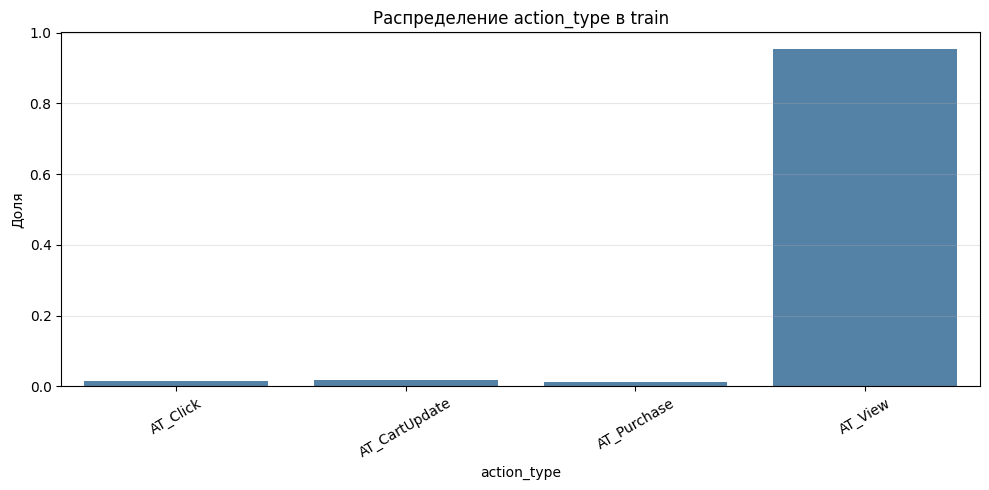

In [8]:
plt.figure(figsize=(10, 5))
sns.barplot(data=action_type_analysis.to_pandas(), x="action_type", y="ratio", color="steelblue")
plt.title("Распределение action_type в train")
plt.ylabel("Доля")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
print(f"Всего товаров в train: {len(train_data["product_id"].unique())}")
print(f"Всего пользователей в train: {len(train_data["user_id"].unique())}")
print(f"Всего уникальных запросов в train: {len(train_data["request_id"].unique())}")

Всего товаров в train: 26522
Всего пользователей в train: 3550
Всего уникальных запросов в train: 667277


In [10]:
mean_actions_in_request = (
    train_data
    .group_by("request_id")
    .agg(pl.len().alias("len"))
)["len"].mean()

print(f"Среднее число взаимодействий в рамках одного запроса: {mean_actions_in_request}")

Среднее число взаимодействий в рамках одного запроса: 24.740271281641657


In [11]:
print(f"Всего категорий в train: {len(train_data["product_category"].unique())}")

Всего категорий в train: 2162


In [12]:
top_categories = (
    train_data.filter(pl.col("action_type").is_in(["AT_CartUpdate", "AT_Purchase"]))
    .group_by("product_category")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
)
top_categories.head(15)

product_category,count
str,u32
"""Расходные материалы (комплекта…",12753
"""Чипсы картофельные""",9806
"""Энергетики классические с саха…",6466
"""Энергетики фруктовые с сахаром""",5331
"""Вода негазированная от 3л""",5049
…,…
"""Эскимо в глазури""",3714
"""Вода минеральная лечебно-столо…",3702
"""Мороженое в вафельном стаканчи…",3562


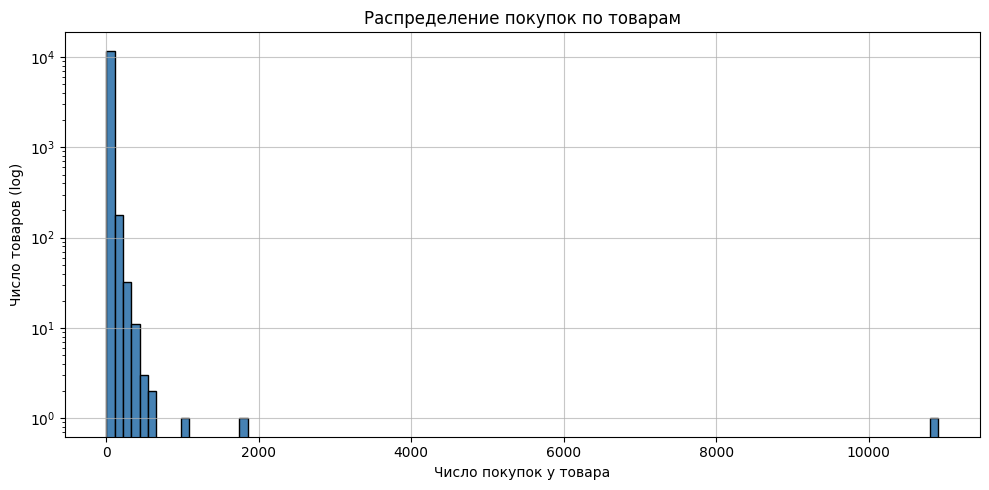

In [13]:
item_counts_purchase = (
    train_data
    .filter(pl.col("action_type") == "AT_Purchase")
    .group_by("product_id")
    .agg(pl.len().alias("count"))
)

# Гистограмма по log-шкале
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(item_counts_purchase["count"].to_numpy(), bins=100, color="steelblue", edgecolor="black")
ax.set_yscale("log")
# ax.set_xscale("log")
ax.set_title("Распределение покупок по товарам")
ax.set_xlabel("Число покупок у товара")
ax.set_ylabel("Число товаров (log)")
ax.grid(alpha=0.7)
plt.tight_layout()
plt.show()

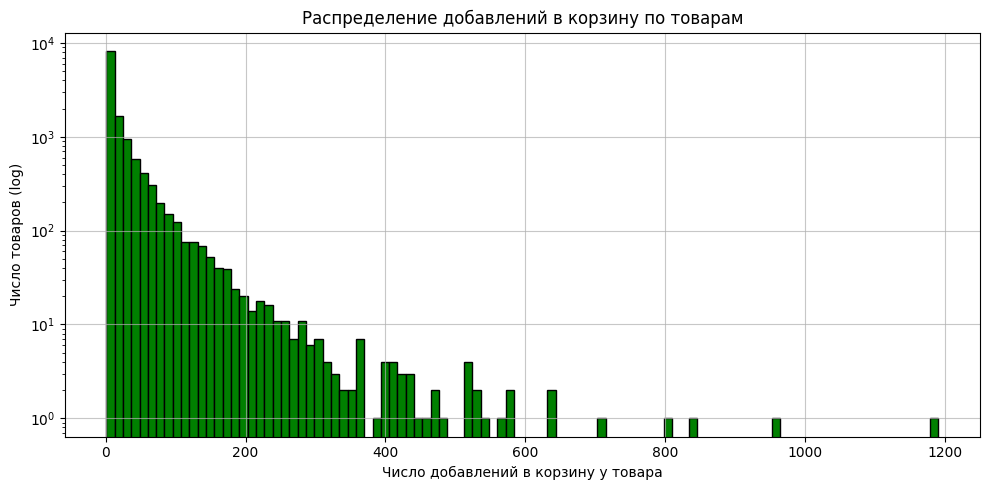

In [14]:
item_counts_cart_update = (
    train_data
    .filter(pl.col("action_type") == "AT_CartUpdate")
    .group_by("product_id")
    .agg(pl.len().alias("count"))
)

# Гистограмма по log-шкале
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(item_counts_cart_update["count"].to_numpy(), bins=100, color="green", edgecolor="black")
ax.set_yscale("log")
# ax.set_xscale("log")
ax.set_title("Распределение добавлений в корзину по товарам")
ax.set_xlabel("Число добавлений в корзину у товара")
ax.set_ylabel("Число товаров (log)")
ax.grid(alpha=0.7)
plt.tight_layout()
plt.show()

In [15]:
city_stats = (
    train_data.filter(pl.col("action_type") == "AT_Purchase")
    .group_by("city_name")
    .agg([
        pl.len().alias("purchases"),
        pl.col("user_id").n_unique().alias("users"),
        pl.col("product_id").n_unique().alias("unique_items")
    ])
    .sort("purchases", descending=True)
)
total = city_stats["purchases"].sum()
city_stats = city_stats.with_columns(
    (pl.col("purchases") / total * 100).round(2).alias("ratio(%)")
)
city_stats

city_name,purchases,users,unique_items,ratio(%)
str,u32,u32,u32,f64
"""Москва""",127153,998,7499,58.71
"""Санкт-Петербург""",41291,388,5144,19.06
"""Нижний Новгород""",10057,96,2393,4.64
"""Екатеринбург""",8655,108,2355,4.0
"""Ростов-на-Дону""",7490,73,1967,3.46
…,…,…,…,…
"""Новосибирск""",5815,108,1903,2.68
"""Иркутск""",988,15,528,0.46
"""Тюмень""",682,26,432,0.31


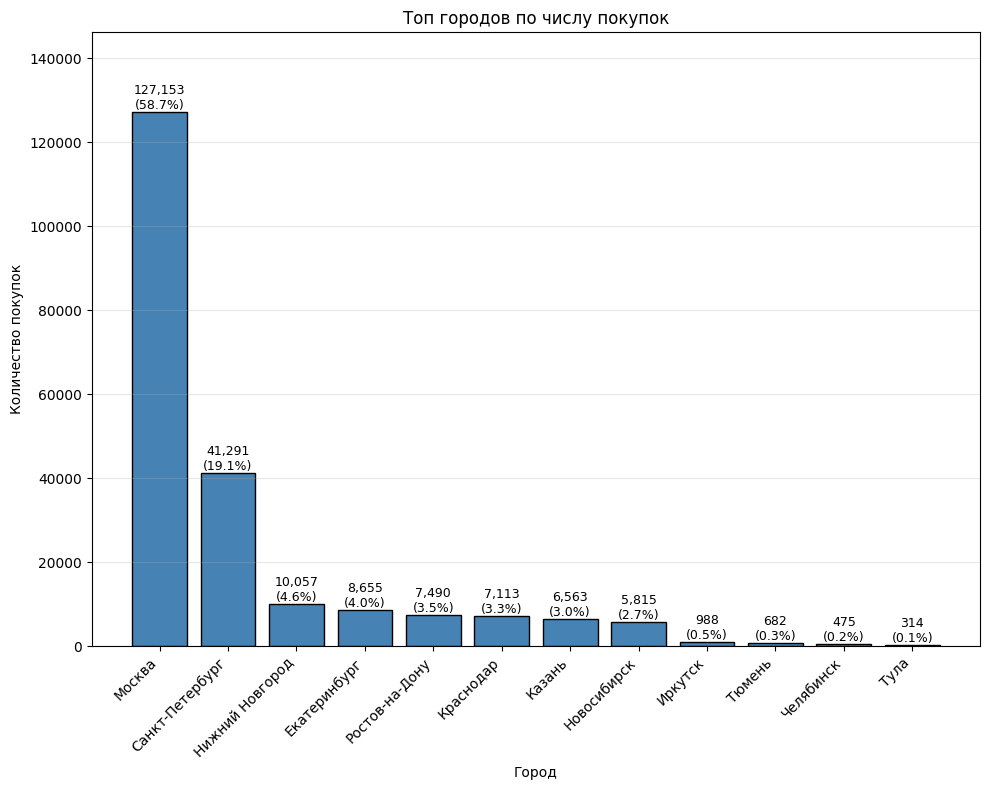

In [16]:
df_plot = city_stats.head(20).to_pandas().sort_values("purchases", ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.bar(df_plot["city_name"].astype(str), df_plot["purchases"], color="steelblue", edgecolor="black")

for bar, cnt, share in zip(bars, df_plot["purchases"], df_plot["ratio(%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(cnt):,}\n({share:.1f}%)",
        ha="center", va="bottom", fontsize=9
    )

ax.set_title("Топ городов по числу покупок")
ax.set_xlabel("Город")
ax.set_ylabel("Количество покупок")
ax.set_ylim(0, df_plot["purchases"].max() * 1.15)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [17]:
train_data.null_count()


action_type,city_name,position_in_request,product_category,product_id,product_image,product_name,request_id,source_type,store_id,timestamp,user_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,401882,0,0,0,0,230814,216596,0,0,0


In [18]:
total = train_data.height
for col in ["position_in_request", "request_id", "source_type"]:
    n = train_data[col].null_count()
    print(f"{col}: {n:,} ({n/total:.2%})")

position_in_request: 401,882 (2.43%)
request_id: 230,814 (1.40%)
source_type: 216,596 (1.31%)


In [19]:

train_data = train_data.with_columns(
    pl.from_epoch(train_data["timestamp"]).alias("date")
)

train_data

action_type,city_name,position_in_request,product_category,product_id,product_image,product_name,request_id,source_type,store_id,timestamp,user_id,date
str,str,i64,str,u64,str,str,u64,str,u64,i64,u64,datetime[μs]
"""AT_View""","""Екатеринбург""",20,"""Колбаса сырокопченая/сыровялен…",15622873057108008619,"""https://avatars.mds.yandex.net…","""Колбаса сервелат-салями Элитна…",9541715973781753063,"""ST_Search""",14539184420433789706,1692527447,7421231689159170748,2023-08-20 10:30:47
"""AT_View""","""Москва""",68,"""ПАСТА С МЯСОМ ПТИЦЫ""",17225686928570569253,"""https://avatars.mds.yandex.net…","""Паста с куриной грудкой в слив…",8471250031114211515,"""ST_Search""",14058715110002771508,1686479624,135364936461809128,2023-06-11 10:33:44
"""AT_View""","""Москва""",8,"""Бумажные полотенца""",9571392871249924586,"""https://avatars.mds.yandex.net…","""Полотенца бумажные Zewa, 4 шт.""",16057244839195726423,"""ST_SearchStartRec""",9463368652572089691,1691202307,7846147652438475366,2023-08-05 02:25:07
"""AT_Purchase""","""Нижний Новгород""",null,"""КОТЛЕТА МЯСНАЯ С ОВОЩАМИ""",2281275230546064866,"""https://avatars.mds.yandex.net…","""Котлета нежная с гречкой и ово…",null,null,4220451351681881198,1683883091,365744836962066469,2023-05-12 09:18:11
"""AT_View""","""Москва""",37,"""Сок яблочный восстановленный о…",6458244614391609220,"""https://avatars.mds.yandex.net…","""Напиток сокосодержащий Яблоко …",11838631385573779102,"""ST_Search""",4666210310211554321,1691893320,13306396713639957054,2023-08-13 02:22:00
…,…,…,…,…,…,…,…,…,…,…,…,…
"""AT_View""","""Санкт-Петербург""",2,"""Творожки""",11951705936862192916,"""https://avatars.mds.yandex.net…","""Творожок двухслойный «Чудо» кл…",17493749790450683112,"""ST_Catalog""",10925691930460199494,1684231541,12011850567211003172,2023-05-16 10:05:41
"""AT_View""","""Москва""",4,"""СЫРНИКИ КЛАССИЧЕСКИЕ""",8082895775749092273,"""https://avatars.mds.yandex.net…","""Сырники из творога без сахара …",1211328052503671082,"""ST_Catalog""",14842344342271362286,1676117867,8190566140622338193,2023-02-11 12:17:47
"""AT_View""","""Москва""",10,"""Другие запеченые хлебцы""",5695100139936509838,"""https://avatars.mds.yandex.net…","""Хлебцы кукурузно-рисовые хруст…",4464637833936249469,"""ST_Catalog""",5663318599009102122,1685754860,16811422400017691818,2023-06-03 01:14:20


In [20]:
min_date = train_data["date"].min().date()
max_date = train_data["date"].max().date()

In [21]:
delta = max_date - min_date

print(f"Минимальная дата: {min_date}")
print(f"Максимальная дата: {max_date}")

print(f"Диапазон: {delta.days} дней ({delta.days / 30:.1f} месяцев)")

Минимальная дата: 2022-12-31
Максимальная дата: 2024-02-02
Диапазон: 398 дней (13.3 месяцев)


In [22]:
test_data.shape

(292826, 11)

In [23]:
test_data.null_count()


index,city_name,product_category,product_id,product_image,product_name,request_id,source_type,store_id,user_id,timestamp
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0


In [24]:
cold_start_users_count = len(set(test_data["user_id"]) - set(train_data["user_id"]))
cold_start_items_count= len(set(test_data["product_id"]) - set(train_data["product_id"]))

print(f"Количество пользователей, которые есть в test, но нет в train: {cold_start_users_count} ({cold_start_users_count/test_data["user_id"].n_unique():.2f}%)")
print(f"Количество товаров, которые есть в test, но нет в train: {cold_start_items_count} ({cold_start_items_count/test_data["product_id"].n_unique():.2f}%)")

Количество пользователей, которые есть в test, но нет в train: 100 (0.12%)
Количество товаров, которые есть в test, но нет в train: 389 (0.03%)


## Выводы по EDA

1. Данные и задача

   Размер train: (16 508 614, 12)
   
   Размер test: (292 826, 11)
   
   Всего в train-части __26 522 товаров__, __3550 пользователей__, __667 277 запросов__

   action_type - __просмотры/клики/добавления в корзину/покупки__

   request_id - идентификатор одной выдачи

2. Таргет

    __Покупки__ составляют __~1%__ от всех взаимодействий, также с добавлениями в корзину и с кликами, а вот __просмотры__ составляют __~95%__ всех взаимодействий

3. Специфика задачи

   На одну выдачу (request_id) в среднем 24 взаимодействий

   Long tail: топ-K товаров покрывают 80% покупок, какой это K?

   Cold-start: в тесте есть __~0.12%__ пользователей и __~0.03%__ товаров, которых нет в train

4. Время

   Минимальная дата: 2022-12-31

   Максимальная дата: 2024-02-02

   Диапазон: 398 дней (13.3 месяцев)


   Test идет __строго__  после train

5. Пропуски

   В train части есть следующие пропуски:

   position_in_request: 401,882 (2.43%), request_id: 230,814 (1.40%), source_type: 216,596 (1.31%)

   В test нет пропусков


   



   
    


## Обработка пропусков

Заменим пропуски в __source_type__ на `unknown`

Пропуски в других столбцах пока что оставим и заменим на этапе формирования датасетов для генерации кандидатов и для ранжирования

In [25]:
# source_type -> unknown
train_data = train_data.with_columns(
    pl.col("source_type").fill_null("unknown")
)

In [26]:
train_data.null_count()

action_type,city_name,position_in_request,product_category,product_id,product_image,product_name,request_id,source_type,store_id,timestamp,user_id,date
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,401882,0,0,0,0,230814,0,0,0,0,0


## Train-Test split

Делить будем по времени - последнюю неделю в тест(валидацию) остально в train

In [27]:
ts_max = train_data["timestamp"].max()
ONE_WEEK = 7 * 24 * 60 * 60
ts_split = ts_max - ONE_WEEK

In [28]:
train_part = train_data.filter(pl.col("timestamp") < ts_split)
val_part = train_data.filter(pl.col("timestamp") >= ts_split)

## Формирование датасета для ранжирования

Удаляем строки, для которых не знаем request_id и position_in_request

В качестве таргета-позитива берем добавления в корзину

In [29]:
df_ranking_train = train_part.filter(
    pl.col("request_id").is_not_null() &
    pl.col("position_in_request").is_not_null()
).with_columns(
    (pl.col("action_type") == "AT_CartUpdate").cast(pl.Int8).alias("target")
)

df_ranking_val = val_part.filter(
    pl.col("request_id").is_not_null() &
    pl.col("position_in_request").is_not_null()
).with_columns(
    (pl.col("action_type") == "AT_CartUpdate").cast(pl.Int8).alias("target")
)

## Формирование df_interactions (для генерации кандидатов)

In [30]:
df_interactions_train = train_part.select([
    "user_id", "product_id", "action_type", "timestamp", "product_category"
])
df_interactions_val = val_part.select([
    "user_id", "product_id", "action_type", "timestamp", "product_category"
])

In [34]:
# полные датасеты
df_ranking_full = train_data.filter(
    pl.col("request_id").is_not_null() &
    pl.col("position_in_request").is_not_null()
).with_columns(
    (pl.col("action_type") == "AT_CartUpdate").cast(pl.Int8).alias("target")
)

df_interactions_full = train_data.select([
    "user_id", "product_id", "action_type", "timestamp", "product_category"
])

In [35]:
# проверяем
print(f"train_part: {train_part.shape}")
print(f"val_part:   {val_part.shape}")

print(f"train: {df_ranking_train.shape}")
print(f"val:   {df_ranking_val.shape}")

print(f"train: {df_interactions_train.shape}")
print(f"val:   {df_interactions_val.shape}")

print(f"train: {df_ranking_train['target'].mean():.4%}")
print(f"val:   {df_ranking_val['target'].mean():.4%}")

train_part: (16175519, 13)
val_part:   (333095, 13)
train: (15769472, 14)
val:   (323736, 14)
train: (16175519, 5)
val:   (333095, 5)
train: 1.9096%
val:   1.9803%


## Сохраняем

In [36]:
Path("data/processed").mkdir(parents=True, exist_ok=True)


df_ranking_train.write_parquet("data/processed/df_ranking_train.parquet")
df_ranking_val.write_parquet("data/processed/df_ranking_val.parquet")
df_ranking_full.write_parquet("data/processed/df_ranking_full.parquet")

df_interactions_train.write_parquet("data/processed/df_interactions_train.parquet")
df_interactions_val.write_parquet("data/processed/df_interactions_val.parquet")
df_interactions_full.write_parquet("data/processed/df_interactions_full.parquet")

test_data.write_parquet("data/processed/df_test.parquet")
